<a href="{{ colab_base_laboratorios }}/Laboratorio_03_intuicion_estadistica_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Lab 3: Intuición estadística

## Model Selection and Train/Validation/Test Sets
[1] Reference http://cs229.stanford.edu/syllabus.html

Just because a learning algorithm fits a training set well, that does not mean it is a good hypothesis. It could over fit and as a result your predictions on the test set would be poor. The error of your hypothesis as measured on the data set with which you trained the parameters will be lower than the error on any other data set.
Given many models with different complexities (for example polynomial degree), we can use a systematic approach to identify the 'best' function. In order to choose the model of your hypothesis, you can test each degree of polynomial and look at the error result.

One way to break down our dataset into the three sets is:
Training set: 60%
Cross validation set: 20%
Test set: 20%

We can now calculate three separate error values for the three different sets using the following method:
1. Optimize the parameters in Θ using the training set for each polynomial degree.
2. Find the polynomial degree d with the least error using the cross validation set.
3. Estimate the generalization error using the test set with J_{test}

This way, the degree of the polynomial d has not been trained using the test set.



## Para entregar


1. Para los modelos generados en la sesión 3 tomar el 20% como datos para realizar el test y el 80% para realizar el entrenamiento y la validacion cruzada (por ejemplo 70% entrenamiento y 10% validacion cruzada). Construir una curva del score en función del parámetro gamma del clasificador que se esta empleando. ¿Cual presenta una mejor solución al problema?.

2. Construir las curvas de aprendizaje estadístico para el modelo descrito, comprobar que la solución es similar a la que se obtiene a través de sklearn. GridSearch: https://scikit-learn.org/stable/modules/grid_search.html

3. Tomando el mejor modelo para los datos ahora van crear nuevos datasets donde el modelo se espera no va a ser optimo sino que presenta overfitting y underfitting. Elegir, los párametros adecuados para los centros de medias y las matrices de covarianzas y mostrar graficamente un ejemplo de overfitting y uno de underfitting con el modelo óptimo anterior. Analizar los resultados.


# Solución

In [ ]:
#Librerias
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, ShuffleSplit
from sklearn.model_selection import learning_curve, GridSearchCV

## Datos
Trabajamos con dos gaussianas en 2D. La clase 0 tiene media $\mu_0 = (1.2, 1.4)$ y la clase 1 tiene media $\mu_1 = (1.4, -1.4)$, con 100 datos por clase y las covarianzas

$$\Sigma_0 = \begin{bmatrix} 1 & -0.8 \\ -0.8 & 1 \end{bmatrix} \qquad \Sigma_1 = \begin{bmatrix} 1 & 0.8 \\ 0.8 & 1 \end{bmatrix}$$

In [ ]:
rv0 = multivariate_normal([1.2, 1.4], [[1.0, -0.8], [-0.8, 1.0]])   # clase 0
rv1 = multivariate_normal([1.4, -1.4], [[1.0, 0.8], [0.8, 1.0]])    # clase 1

X0 = rv0.rvs(100, random_state=10)
X1 = rv1.rvs(100, random_state=11)

X = np.concatenate([X0, X1])
y = np.concatenate([np.zeros(100), np.ones(100)])

print("Dimensiones de X =", X.shape)

Dimensiones de X = (200, 2)


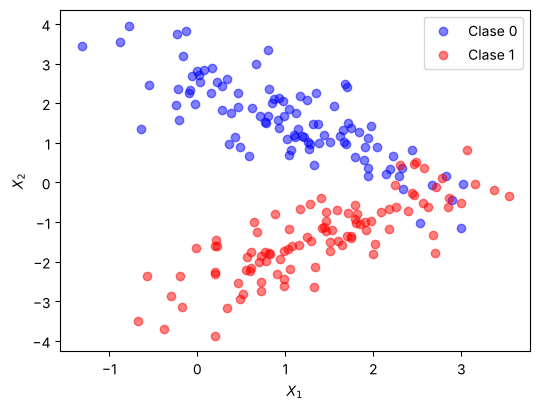

In [ ]:
plt.figure(figsize=(5.5, 4.2))
plt.plot(X[y == 0][:, 0], X[y == 0][:, 1], "bo", alpha=0.5, label="Clase 0")
plt.plot(X[y == 1][:, 0], X[y == 1][:, 1], "ro", alpha=0.5, label="Clase 1")
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.legend()
plt.tight_layout()
plt.show()

Como conocemos las distribuciones de donde salen los datos, podemos usar el clasificador de Bayes como referencia. Este asigna la clase 1 cuando $f_1(x) > f_0(x)$ y es el mejor resultado posible, así que nos sirve para saber si el SVC está cerca o lejos de lo ideal.

# 1. score en función de gamma

Primero separamos el 20 % para test. El 80 % restante lo dividimos en entrenamiento, que es el 70 % del total, y validación, que es el 10 % del total. Como la validación se saca del 80 %, la fracción que hay que pedir es $0.10/0.80 = 0.125$.

In [ ]:
X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

print("Datos para test =", len(y_test))
print("Datos para entrenamiento y validación =", len(y_resto))

Datos para test = 40
Datos para entrenamiento y validación = 160


Con solo 20 datos de validación el score cambia de a 0.05, así que una sola partición da una curva muy ruidosa. Por eso repetimos la división entre entrenamiento y validación 20 veces con `ShuffleSplit` y promediamos.

In [ ]:
particiones = ShuffleSplit(n_splits=20, test_size=0.125, random_state=0)

# revisamos los tamaños en la primera partición
for i_train, i_val in particiones.split(X_resto):
    print("Datos de entrenamiento =", len(i_train))
    print("Datos de validación =", len(i_val))
    break

Datos de entrenamiento = 140
Datos de validación = 20


Para cada valor de $\gamma$ entrenamos un SVC en cada una de las 20 particiones y guardamos el promedio del score de entrenamiento y el de validación.

In [ ]:
gammas = np.logspace(-3, 3, 25)   # de 0.001 a 1000

score_train = []
score_val = []

for g in gammas:
    s_train = []
    s_val = []

    for i_train, i_val in particiones.split(X_resto):
        modelo = SVC(gamma=g)
        modelo.fit(X_resto[i_train], y_resto[i_train])

        s_train.append(modelo.score(X_resto[i_train], y_resto[i_train]))
        s_val.append(modelo.score(X_resto[i_val], y_resto[i_val]))

    score_train.append(np.mean(s_train))
    score_val.append(np.mean(s_val))

score_train = np.array(score_train)
score_val = np.array(score_val)

In [ ]:
for i in range(len(gammas)):
    print("gamma =", round(gammas[i], 4), "  train =", round(score_train[i], 3), "  validación =", round(score_val[i], 3))

gamma = 0.001   train = 0.911   validación = 0.88
gamma = 0.0018   train = 0.921   validación = 0.9
gamma = 0.0032   train = 0.92   validación = 0.905
gamma = 0.0056   train = 0.925   validación = 0.905
gamma = 0.01   train = 0.925   validación = 0.905
gamma = 0.0178   train = 0.924   validación = 0.908
gamma = 0.0316   train = 0.926   validación = 0.912
gamma = 0.0562   train = 0.928   validación = 0.917
gamma = 0.1   train = 0.929   validación = 0.917
gamma = 0.1778   train = 0.936   validación = 0.917
gamma = 0.3162   train = 0.94   validación = 0.93
gamma = 0.5623   train = 0.946   validación = 0.935
gamma = 1.0   train = 0.95   validación = 0.935
gamma = 1.7783   train = 0.953   validación = 0.922
gamma = 3.1623   train = 0.964   validación = 0.91
gamma = 5.6234   train = 0.973   validación = 0.908
gamma = 10.0   train = 0.986   validación = 0.898
gamma = 17.7828   train = 0.993   validación = 0.87
gamma = 31.6228   train = 1.0   validación = 0.83
gamma = 56.2341   train = 1.0   v

In [ ]:
gamma_optimo = gammas[np.argmax(score_val)]

print("Mejor gamma =", round(gamma_optimo, 4))
print("Score de validación =", round(np.max(score_val), 3))

Mejor gamma = 0.5623
Score de validación = 0.935


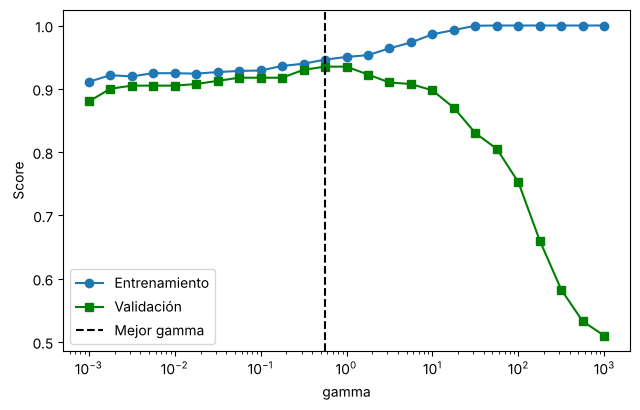

In [ ]:
plt.figure(figsize=(6.5, 4.2))
plt.semilogx(gammas, score_train, "o-", label="Entrenamiento")
plt.semilogx(gammas, score_val, "s-", color="g", label="Validación")
plt.axvline(gamma_optimo, color="k", linestyle="--", label="Mejor gamma")
plt.xlabel("gamma")
plt.ylabel("Score")
plt.legend()
plt.tight_layout()
plt.show()

Con el mejor gamma entrenamos con todo el 80 % y medimos una sola vez en test. También calculamos el score del clasificador de Bayes en los mismos datos de test.

In [ ]:
modelo_optimo = SVC(gamma=gamma_optimo)
modelo_optimo.fit(X_resto, y_resto)

prediccion_bayes = rv1.pdf(X_test) > rv0.pdf(X_test)

print("Score de entrenamiento =", round(modelo_optimo.score(X_resto, y_resto), 3))
print("Score de test =", round(modelo_optimo.score(X_test, y_test), 3))
print("Score de Bayes en test =", round(np.mean(prediccion_bayes == y_test), 3))

Score de entrenamiento = 0.944
Score de test = 0.975
Score de Bayes en test = 0.975


Para ver qué significa cada zona de la curva, graficamos la frontera para un gamma muy pequeño, el óptimo y uno muy grande. La línea negra punteada es la frontera de Bayes.

gamma = 0.001   train = 0.925   test = 0.95
gamma = 0.562   train = 0.944   test = 0.975


gamma = 100   train = 1.0   test = 0.675


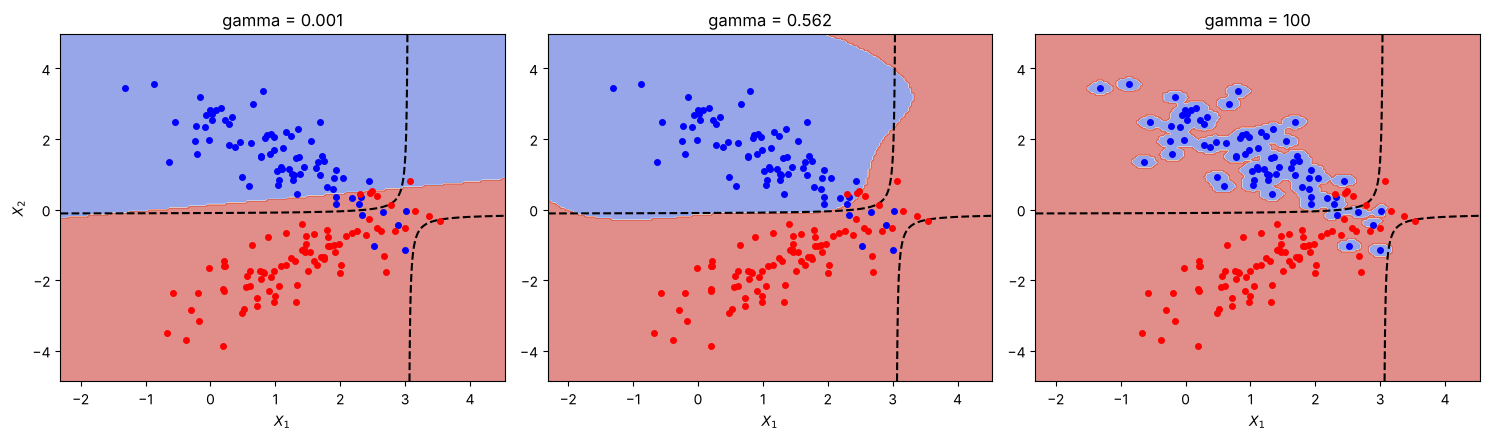

In [ ]:
gammas_ejemplo = [0.001, gamma_optimo, 100]

x1 = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200)
x2 = np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200)
xx, yy = np.meshgrid(x1, x2)
malla = np.c_[xx.ravel(), yy.ravel()]

Z_bayes = (rv1.pdf(malla) - rv0.pdf(malla)).reshape(xx.shape)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))

for i in range(3):
    modelo = SVC(gamma=gammas_ejemplo[i])
    modelo.fit(X_resto, y_resto)
    Z = modelo.predict(malla).reshape(xx.shape)

    ejes[i].contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.6)
    ejes[i].contour(xx, yy, Z_bayes, levels=[0], colors="k", linestyles="--")
    ejes[i].plot(X_resto[y_resto == 0][:, 0], X_resto[y_resto == 0][:, 1], "bo", markersize=4)
    ejes[i].plot(X_resto[y_resto == 1][:, 0], X_resto[y_resto == 1][:, 1], "ro", markersize=4)
    ejes[i].set_title("gamma = " + str(round(gammas_ejemplo[i], 3)))
    ejes[i].set_xlabel("$X_1$")

    print("gamma =", round(gammas_ejemplo[i], 3),
          "  train =", round(modelo.score(X_resto, y_resto), 3),
          "  test =", round(modelo.score(X_test, y_test), 3))

ejes[0].set_ylabel("$X_2$")
plt.tight_layout()
plt.show()

### Análisis
La curva tiene tres zonas.

Para gamma pequeño, menor a 0.1, el score de entrenamiento y el de validación están juntos, alrededor de 0.91 y 0.92. El modelo es muy simple y su frontera es casi una línea recta. Como en este problema las clases se separan casi con una recta, quedarse corto en complejidad cuesta poco, pero se ve que la frontera no sigue la curvatura de la frontera de Bayes en la esquina inferior derecha.

Entre 0.3 y 1 está el máximo de validación, 0.935. El mejor valor es $\gamma \approx 0.56$, que empata con $\gamma = 1$, y `argmax` toma el primero. Con este valor el score en test es 0.975, igual al del clasificador de Bayes en esos mismos datos, y la frontera sigue a la de Bayes donde hay datos. Por eso el SVC con $\gamma \approx 0.56$ es el que mejor resuelve el problema.

Para gamma grande, mayor a 10, el score de entrenamiento llega a 1 mientras el de validación cae hasta 0.51 en $\gamma = 1000$, que es lo mismo que adivinar. En la frontera con $\gamma = 100$ se ven islas alrededor de cada punto azul y el test baja a 0.68. El modelo memoriza los datos de entrenamiento y no generaliza.

Entre 0.3 y 1.8 los scores de validación se diferencian en menos de 0.02, y eso es menos de lo que vale un solo dato de validación (0.05). Cualquier gamma en ese rango es una buena solución y tomamos $\gamma = 0.56$. El test (0.975) sale mayor que la validación (0.935) porque son solo 40 datos y cada uno vale 0.025, no porque el modelo sea mejor en test.

# 2. curvas de aprendizaje

## 2.1 Curva de aprendizaje hecha a mano
Usamos el gamma óptimo y seguimos estos pasos.

1. Usamos las mismas 20 particiones del 80 % de los datos.
2. Para cada tamaño $n$ tomamos los primeros $n$ índices de entrenamiento de cada partición. Los índices de `ShuffleSplit` ya vienen en orden aleatorio, así que es un subconjunto al azar.
3. Entrenamos con esos $n$ datos y calculamos el score sobre esos mismos datos y sobre toda la validación.
4. Promediamos sobre las 20 particiones.

In [ ]:
tamanos = np.array([10, 20, 40, 60, 80, 100, 120, 140])

curva_train = []
curva_val = []

for n in tamanos:
    s_train = []
    s_val = []

    for i_train, i_val in particiones.split(X_resto):
        i_sub = i_train[:n]   # primeros n datos de entrenamiento

        modelo = SVC(gamma=gamma_optimo)
        modelo.fit(X_resto[i_sub], y_resto[i_sub])

        s_train.append(modelo.score(X_resto[i_sub], y_resto[i_sub]))
        s_val.append(modelo.score(X_resto[i_val], y_resto[i_val]))

    curva_train.append(np.mean(s_train))
    curva_val.append(np.mean(s_val))

curva_train = np.array(curva_train)
curva_val = np.array(curva_val)

## 2.2 La misma curva con sklearn
`learning_curve` hace lo mismo si le pasamos las mismas particiones y los mismos tamaños.

In [ ]:
tamanos_sk, train_sk, val_sk = learning_curve(SVC(gamma=gamma_optimo), X_resto, y_resto,
                                              train_sizes=tamanos, cv=particiones)

# cada fila es un tamaño y cada columna una partición
curva_train_sk = train_sk.mean(axis=1)
curva_val_sk = val_sk.mean(axis=1)

print("Diferencia máxima en entrenamiento =", np.max(np.abs(curva_train_sk - curva_train)))
print("Diferencia máxima en validación =", np.max(np.abs(curva_val_sk - curva_val)))

Diferencia máxima en entrenamiento = 2.220446049250313e-16
Diferencia máxima en validación = 2.220446049250313e-16


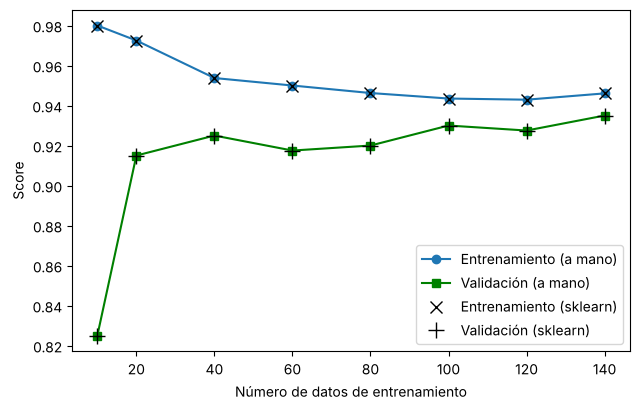

In [ ]:
plt.figure(figsize=(6.5, 4.2))
plt.plot(tamanos, curva_train, "o-", label="Entrenamiento (a mano)")
plt.plot(tamanos, curva_val, "s-", color="g", label="Validación (a mano)")
plt.plot(tamanos_sk, curva_train_sk, "kx", markersize=9, label="Entrenamiento (sklearn)")
plt.plot(tamanos_sk, curva_val_sk, "k+", markersize=11, label="Validación (sklearn)")
plt.xlabel("Número de datos de entrenamiento")
plt.ylabel("Score")
plt.legend()
plt.tight_layout()
plt.show()

## 2.3 Búsqueda de gamma con GridSearchCV
Repetimos la búsqueda de la parte 1 con `GridSearchCV`, usando los mismos gammas y las mismas particiones.

In [ ]:
busqueda = GridSearchCV(SVC(), param_grid={"gamma": gammas}, cv=particiones)
busqueda.fit(X_resto, y_resto)

print("Mejor gamma con GridSearchCV =", round(busqueda.best_params_["gamma"], 4))
print("Mejor gamma a mano =", round(gamma_optimo, 4))
print("Diferencia máxima en validación =", np.max(np.abs(busqueda.cv_results_["mean_test_score"] - score_val)))
print("Score de test con GridSearchCV =", round(busqueda.score(X_test, y_test), 3))

Mejor gamma con GridSearchCV = 0.5623
Mejor gamma a mano = 0.5623
Diferencia máxima en validación = 0.0
Score de test con GridSearchCV = 0.975


### Análisis
La curva de aprendizaje hecha a mano y la de `learning_curve` coinciden hasta el error de redondeo de la máquina ($2 \times 10^{-16}$). `GridSearchCV` elige el mismo gamma, con los mismos scores promedio y el mismo score en test. Esto pasa porque usamos las mismas particiones (`ShuffleSplit` con `random_state=0`) y los mismos tamaños. Con particiones diferentes los números cambiarían un poco por el ruido, pero el gamma óptimo quedaría en la misma zona.

En la curva de aprendizaje, con 10 datos el modelo saca 0.98 en entrenamiento y 0.825 en validación. Hay una brecha grande porque con tan pocos datos el modelo se ajusta a esos puntos en particular. A partir de unos 40 datos las dos curvas se estabilizan entre 0.91 y 0.95, y con 140 datos la brecha es de apenas 0.01. Las dos curvas quedan altas y juntas, que es lo que se espera de un buen ajuste. Agregar más datos ya no mejoraría mucho el resultado.

# 3. overfitting y underfitting

Ahora el modelo queda fijo, un SVC con el gamma óptimo de la parte 1, y lo que cambiamos son los datos. Para cada caso se entrena de nuevo con los datos nuevos, usando ese mismo gamma.

El hiperparámetro gamma define la complejidad de la frontera de decisión. Aquí no cambiamos gamma. Buscamos datos con los que ese gamma resulte demasiado complejo, que es el overfitting, y datos con los que resulte demasiado simple, que es el underfitting. Elegimos las medias y las covarianzas con ese objetivo y comparamos siempre con la frontera de Bayes.

## Elección de los parámetros
El SVC que usamos tiene kernel RBF, que es el que trae sklearn por defecto. Este kernel mide qué tan cerca están dos puntos con

$$K(x, x') = \exp\left(-\gamma \lVert x - x' \rVert^2\right)$$

Cada dato de entrenamiento influye sobre los puntos que tiene cerca, y el alcance de esa influencia es aproximadamente $\ell = 1/\sqrt{\gamma}$. Lo que importa es comparar $\ell$ con el tamaño de los datos, que lo fijan las desviaciones estándar de las covarianzas.

1. Si los datos son mucho más grandes que $\ell$, cada punto queda casi aislado y el modelo se ajusta a cada dato. Esperamos overfitting.
2. Si los datos son mucho más pequeños que $\ell$, el modelo es demasiado suave y la frontera no puede doblarse lo suficiente. Esperamos underfitting.

In [ ]:
print("Alcance de cada dato l =", round(1 / np.sqrt(gamma_optimo), 3))
print("Desviación estándar de los datos originales = 1")

Alcance de cada dato l = 1.334
Desviación estándar de los datos originales = 1


En los datos originales la desviación estándar es del mismo orden que $\ell$, y por eso el ajuste es bueno. Para escoger los parámetros de los nuevos datasets probamos varios tamaños con el mismo gamma óptimo y nos quedamos con el primero en el que aparece el comportamiento buscado.

Para el overfitting multiplicamos las medias por un factor $k$ y las covarianzas por $k^2$, con 50 datos por clase. Para cada factor repetimos 50 particiones entre entrenamiento y validación sobre el 80 % de los datos.

In [ ]:
factores = [1, 2, 3, 4, 5]
particiones_k = ShuffleSplit(n_splits=50, test_size=0.125, random_state=0)

for k in factores:
    rv0_k = multivariate_normal(k * np.array([1.2, 1.4]), k**2 * np.array([[1.0, -0.8], [-0.8, 1.0]]))
    rv1_k = multivariate_normal(k * np.array([1.4, -1.4]), k**2 * np.array([[1.0, 0.8], [0.8, 1.0]]))

    X_k = np.concatenate([rv0_k.rvs(50, random_state=10), rv1_k.rvs(50, random_state=11)])
    y_k = np.concatenate([np.zeros(50), np.ones(50)])
    Xk_resto, Xk_test, yk_resto, yk_test = train_test_split(X_k, y_k, test_size=0.2, random_state=1)

    s_train = []
    s_val = []

    for i_train, i_val in particiones_k.split(Xk_resto):
        modelo = SVC(gamma=gamma_optimo)
        modelo.fit(Xk_resto[i_train], yk_resto[i_train])

        s_train.append(modelo.score(Xk_resto[i_train], yk_resto[i_train]))
        s_val.append(modelo.score(Xk_resto[i_val], yk_resto[i_val]))

    print("factor =", k, "  train =", round(np.mean(s_train), 3), "  validación =", round(np.mean(s_val), 3))

factor = 1   train = 0.986   validación = 0.962


factor = 2   train = 0.989   validación = 0.962


factor = 3   train = 0.996   validación = 0.958


factor = 4   train = 1.0   validación = 0.912


factor = 5   train = 1.0   validación = 0.886


Con los factores 1, 2 y 3 la validación se queda alrededor de 0.96, así que todavía no hay overfitting. Con el factor 4 el entrenamiento llega a 1 y la validación baja a 0.91, y con el 5 baja a 0.89. Usamos el 4, que es el más pequeño con el que se ve claro el overfitting. Con este factor la desviación estándar es 4, unas 3 veces $\ell$.

Multiplicar los datos por $k$ tiene el mismo efecto que multiplicar gamma por $k^2$ sobre los datos originales. El factor 4 equivale entonces a $\gamma \approx 16 \times 0.56 \approx 9$, y en la curva de la parte 1 ese valor está donde el entrenamiento se acerca a 1 y la validación empieza a caer.

Para el underfitting usamos la forma de X con desviaciones estándar cada vez más pequeñas y 200 datos por clase.

In [ ]:
desviaciones = [1.0, 0.5, 0.3, 0.2, 0.1]

for s in desviaciones:
    rv0_s = multivariate_normal([0.0, 0.0], s**2 * np.array([[1.0, -0.9], [-0.9, 1.0]]))
    rv1_s = multivariate_normal([0.0, 0.0], s**2 * np.array([[1.0, 0.9], [0.9, 1.0]]))

    X_s = np.concatenate([rv0_s.rvs(200, random_state=10), rv1_s.rvs(200, random_state=11)])
    y_s = np.concatenate([np.zeros(200), np.ones(200)])
    Xs_resto, Xs_test, ys_resto, ys_test = train_test_split(X_s, y_s, test_size=0.2, random_state=1)

    s_train = []
    s_val = []

    for i_train, i_val in particiones_k.split(Xs_resto):
        modelo = SVC(gamma=gamma_optimo)
        modelo.fit(Xs_resto[i_train], ys_resto[i_train])

        s_train.append(modelo.score(Xs_resto[i_train], ys_resto[i_train]))
        s_val.append(modelo.score(Xs_resto[i_val], ys_resto[i_val]))

    print("desviación =", s, "  train =", round(np.mean(s_train), 3), "  validación =", round(np.mean(s_val), 3))

desviación = 1.0   train = 0.861   validación = 0.868


desviación = 0.5   train = 0.826   validación = 0.839


desviación = 0.3   train = 0.769   validación = 0.78


desviación = 0.2   train = 0.648   validación = 0.637


desviación = 0.1   train = 0.522   validación = 0.51


Con desviación 1 el modelo ajusta bien y entrenamiento y validación quedan cerca de 0.86 y 0.87. Al reducir la desviación los dos scores bajan juntos. Con 0.3 la validación es 0.78, con 0.2 es 0.64 y con 0.1 es 0.51, que es lo mismo que adivinar. Usamos 0.1, donde el modelo ya no aprende nada. Con esta desviación $\ell \approx 1.3$ es unas 13 veces el tamaño de los datos, y equivale a usar $\gamma \approx 0.01 \times 0.56 \approx 0.006$ sobre la misma X con desviación 1.

## 3.1 Overfitting
Tomamos el mismo problema pero 4 veces más grande. Las medias se multiplican por 4 y las covarianzas por $4^2 = 16$, así que las desviaciones estándar pasan de 1 a 4. La forma del problema es la misma y la frontera de Bayes también, solo que escalada. Además usamos pocos datos, 50 por clase.

$$\mu_0 = (4.8, 5.6) \qquad \Sigma_0 = \begin{bmatrix} 16 & -12.8 \\ -12.8 & 16 \end{bmatrix}$$

$$\mu_1 = (5.6, -5.6) \qquad \Sigma_1 = \begin{bmatrix} 16 & 12.8 \\ 12.8 & 16 \end{bmatrix}$$

In [ ]:
rv0_over = multivariate_normal([4.8, 5.6], [[16.0, -12.8], [-12.8, 16.0]])
rv1_over = multivariate_normal([5.6, -5.6], [[16.0, 12.8], [12.8, 16.0]])

X0 = rv0_over.rvs(50, random_state=10)
X1 = rv1_over.rvs(50, random_state=11)

X_over = np.concatenate([X0, X1])
y_over = np.concatenate([np.zeros(50), np.ones(50)])

Xo_resto, Xo_test, yo_resto, yo_test = train_test_split(X_over, y_over, test_size=0.2, random_state=1)

In [ ]:
modelo_over = SVC(gamma=gamma_optimo)
modelo_over.fit(Xo_resto, yo_resto)

prediccion_bayes = rv1_over.pdf(Xo_test) > rv0_over.pdf(Xo_test)

print("Score de entrenamiento =", round(modelo_over.score(Xo_resto, yo_resto), 3))
print("Score de test =", round(modelo_over.score(Xo_test, yo_test), 3))
print("Score de Bayes en test =", round(np.mean(prediccion_bayes == yo_test), 3))

Score de entrenamiento = 1.0
Score de test = 0.8
Score de Bayes en test = 0.85


In [ ]:
particiones_over = ShuffleSplit(n_splits=50, test_size=0.125, random_state=0)

n_over, train_over, val_over = learning_curve(SVC(gamma=gamma_optimo), Xo_resto, yo_resto,
                                              train_sizes=np.linspace(0.2, 1.0, 6),
                                              cv=particiones_over)

print("Entrenamiento =", np.round(train_over.mean(axis=1), 3))
print("Validación =", np.round(val_over.mean(axis=1), 3))

Entrenamiento = [0.999 0.998 0.999 0.999 0.999 1.   ]
Validación = [0.67  0.796 0.886 0.902 0.924 0.912]


Para graficar la frontera evaluamos el modelo en una malla de puntos. La línea negra punteada es la frontera de Bayes, donde las dos densidades son iguales. Al lado ponemos la curva de aprendizaje.

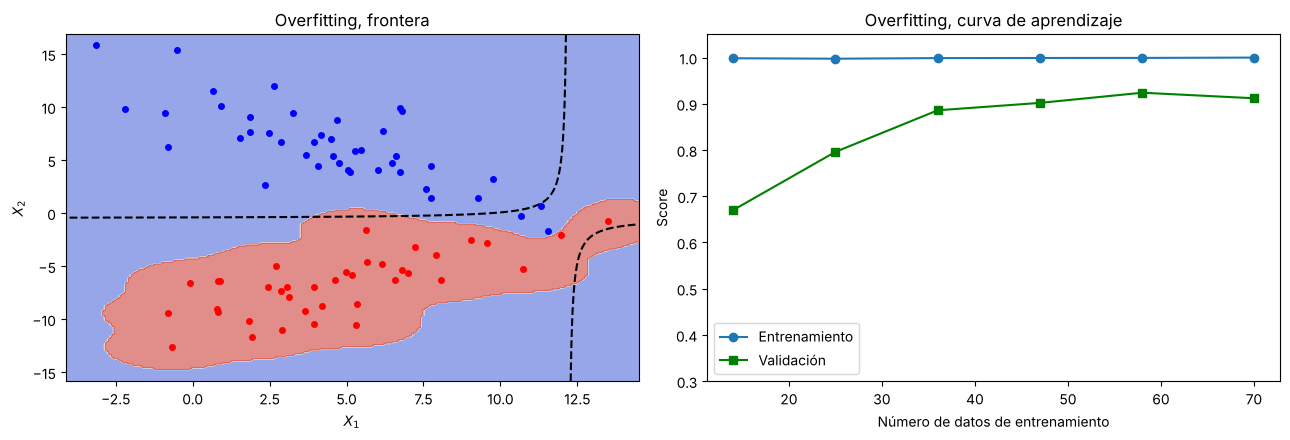

In [ ]:
x1 = np.linspace(X_over[:, 0].min() - 1, X_over[:, 0].max() + 1, 200)
x2 = np.linspace(X_over[:, 1].min() - 1, X_over[:, 1].max() + 1, 200)
xx, yy = np.meshgrid(x1, x2)
malla = np.c_[xx.ravel(), yy.ravel()]

Z = modelo_over.predict(malla).reshape(xx.shape)
Z_bayes = (rv1_over.pdf(malla) - rv0_over.pdf(malla)).reshape(xx.shape)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

ejes[0].contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.6)
ejes[0].contour(xx, yy, Z_bayes, levels=[0], colors="k", linestyles="--")
ejes[0].plot(Xo_resto[yo_resto == 0][:, 0], Xo_resto[yo_resto == 0][:, 1], "bo", markersize=4)
ejes[0].plot(Xo_resto[yo_resto == 1][:, 0], Xo_resto[yo_resto == 1][:, 1], "ro", markersize=4)
ejes[0].set_xlabel("$X_1$")
ejes[0].set_ylabel("$X_2$")
ejes[0].set_title("Overfitting, frontera")

ejes[1].plot(n_over, train_over.mean(axis=1), "o-", label="Entrenamiento")
ejes[1].plot(n_over, val_over.mean(axis=1), "s-", color="g", label="Validación")
ejes[1].set_ylim(0.3, 1.05)
ejes[1].set_xlabel("Número de datos de entrenamiento")
ejes[1].set_ylabel("Score")
ejes[1].set_title("Overfitting, curva de aprendizaje")
ejes[1].legend()

plt.tight_layout()
plt.show()

### Análisis
El score de entrenamiento es prácticamente 1 para todos los tamaños, mientras el de validación arranca en 0.67 con 14 datos y se queda entre 0.90 y 0.92 desde unos 47 datos. En test el modelo saca 0.80 y Bayes 0.85. Esa diferencia grande entre entrenamiento y validación es la señal del overfitting.

En la frontera se ve que el modelo solo reconoce la clase 1 en una mancha pegada a los puntos rojos de entrenamiento y todo lo demás lo manda a la clase 0. Eso incluye la zona inferior derecha, que según Bayes es de la clase 1. Un dato rojo nuevo que caiga un poco por fuera de esa mancha estara mal clasificado.

Con el mismo gamma, el modelo pasó de ajustar bien los datos originales a ajustar demasiado los de entrenamiento. Es el mismo comportamiento que vimos en la parte 1 con gamma grande, entrenamiento en 1 y validación más baja, solo que aquí el gamma es el óptimo y lo que cambió fueron los datos.

## 3.2 Underfitting
Para el underfitting necesitamos que la frontera de Bayes sea curva y que los datos estén poco dispersos. Usamos dos gaussianas centradas en el mismo punto pero con correlaciones opuestas, así los datos forman una X. La clase 1 ocupa los cuadrantes 1 y 3 y la clase 0 los cuadrantes 2 y 4, entonces la frontera de Bayes son los dos ejes y no exite n ninguna línea recta que pueda separarlas. Las hacemos pequeñas, con desviación estándar 0.1, y usamos 200 datos por clase.

$$\mu_0 = \mu_1 = (0, 0) \qquad \Sigma_0 = \begin{bmatrix} 0.01 & -0.009 \\ -0.009 & 0.01 \end{bmatrix} \qquad \Sigma_1 = \begin{bmatrix} 0.01 & 0.009 \\ 0.009 & 0.01 \end{bmatrix}$$

In [ ]:
rv0_under = multivariate_normal([0.0, 0.0], [[0.01, -0.009], [-0.009, 0.01]])
rv1_under = multivariate_normal([0.0, 0.0], [[0.01, 0.009], [0.009, 0.01]])

X0 = rv0_under.rvs(200, random_state=10)
X1 = rv1_under.rvs(200, random_state=11)

X_under = np.concatenate([X0, X1])
y_under = np.concatenate([np.zeros(200), np.ones(200)])

Xu_resto, Xu_test, yu_resto, yu_test = train_test_split(X_under, y_under, test_size=0.2, random_state=1)

In [ ]:
modelo_under = SVC(gamma=gamma_optimo)
modelo_under.fit(Xu_resto, yu_resto)

prediccion_bayes = rv1_under.pdf(Xu_test) > rv0_under.pdf(Xu_test)

print("Score de entrenamiento =", round(modelo_under.score(Xu_resto, yu_resto), 3))
print("Score de test =", round(modelo_under.score(Xu_test, yu_test), 3))
print("Score de Bayes en test =", round(np.mean(prediccion_bayes == yu_test), 3))

Score de entrenamiento = 0.522
Score de test = 0.412
Score de Bayes en test = 0.838


In [ ]:
particiones_under = ShuffleSplit(n_splits=50, test_size=0.125, random_state=0)

n_under, train_under, val_under = learning_curve(SVC(gamma=gamma_optimo), Xu_resto, yu_resto,
                                              train_sizes=np.linspace(0.2, 1.0, 6),
                                              cv=particiones_under)

print("Entrenamiento =", np.round(train_under.mean(axis=1), 3))
print("Validación =", np.round(val_under.mean(axis=1), 3))

Entrenamiento = [0.564 0.547 0.533 0.534 0.527 0.522]
Validación = [0.498 0.497 0.503 0.509 0.497 0.51 ]


Para graficar la frontera evaluamos el modelo en una malla de puntos. La línea negra punteada es la frontera de Bayes, donde las dos densidades son iguales. Al lado ponemos la curva de aprendizaje.

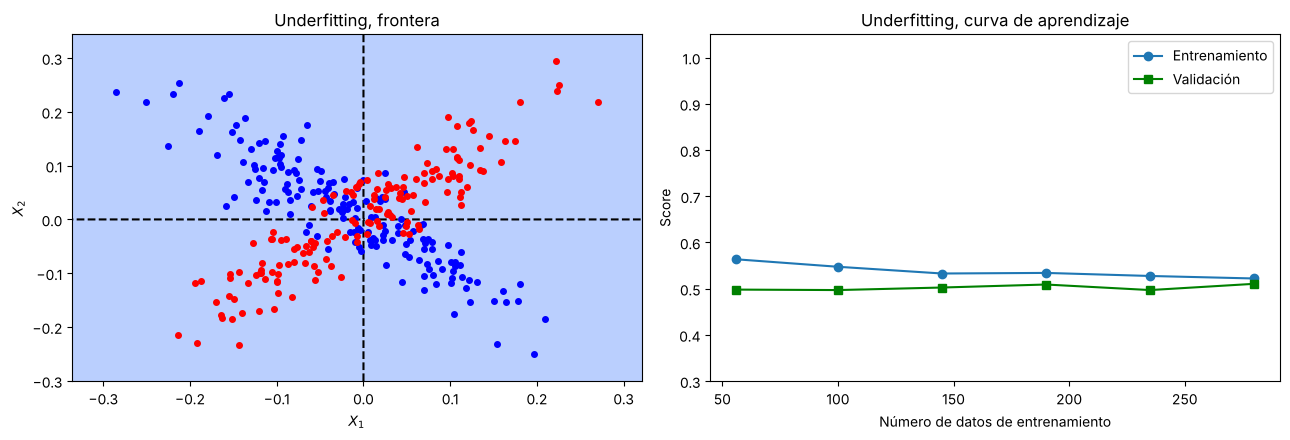

In [ ]:
x1 = np.linspace(X_under[:, 0].min() - 0.05, X_under[:, 0].max() + 0.05, 200)
x2 = np.linspace(X_under[:, 1].min() - 0.05, X_under[:, 1].max() + 0.05, 200)
xx, yy = np.meshgrid(x1, x2)
malla = np.c_[xx.ravel(), yy.ravel()]

Z = modelo_under.predict(malla).reshape(xx.shape)
Z_bayes = (rv1_under.pdf(malla) - rv0_under.pdf(malla)).reshape(xx.shape)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

ejes[0].contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.6)
ejes[0].contour(xx, yy, Z_bayes, levels=[0], colors="k", linestyles="--")
ejes[0].plot(Xu_resto[yu_resto == 0][:, 0], Xu_resto[yu_resto == 0][:, 1], "bo", markersize=4)
ejes[0].plot(Xu_resto[yu_resto == 1][:, 0], Xu_resto[yu_resto == 1][:, 1], "ro", markersize=4)
ejes[0].set_xlabel("$X_1$")
ejes[0].set_ylabel("$X_2$")
ejes[0].set_title("Underfitting, frontera")

ejes[1].plot(n_under, train_under.mean(axis=1), "o-", label="Entrenamiento")
ejes[1].plot(n_under, val_under.mean(axis=1), "s-", color="g", label="Validación")
ejes[1].set_ylim(0.3, 1.05)
ejes[1].set_xlabel("Número de datos de entrenamiento")
ejes[1].set_ylabel("Score")
ejes[1].set_title("Underfitting, curva de aprendizaje")
ejes[1].legend()

plt.tight_layout()
plt.show()

### Análisis
El score de entrenamiento queda entre 0.52 y 0.56 y el de validación alrededor de 0.50. Los dos son casi iguales a adivinar al azar y están muy lejos de Bayes, que saca 0.84 en test. Las curvas son planas y pasar de 56 a 280 datos no cambia nada. Que entrenamiento y validación sean igual de malos y que más datos no ayuden es la señal del underfitting. Al modelo no le faltan datos, le falta flexibilidad.

En la frontera todo el plano queda de un solo color, así que el modelo predice la misma clase para todo. Para separar la X hace falta una frontera que cambie de clase en cada cuadrante, y con este gamma el modelo es demasiado simple para dibujarla, por eso su frontera no se parece a la de Bayes.

El score de test (0.41) sale por debajo de 0.5. No significa que el modelo sea peor que adivinar, es ruido de una sola partición de 80 datos. La curva de aprendizaje promedia 50 particiones y muestra que la validación está en 0.50.

## Conclusiones
Para estos datos el mejor clasificador es el SVC con $\gamma \approx 0.56$, con score de 0.975 en test, igual al de Bayes. Cualquier valor entre 0.3 y 1.8 da resultados equivalentes dentro del ruido.

Las curvas de score contra gamma y de aprendizaje hechas a mano dan exactamente lo mismo que `learning_curve` y `GridSearchCV` cuando se usan las mismas particiones.

Un mismo modelo puede ser óptimo para un dataset y malo para otro. Con el gamma óptimo, datos más dispersos y pocos dieron overfitting, con entrenamiento en 1 y una diferencia grande con la validación, y datos poco dispersos dieron underfitting, con entrenamiento y validación bajos, juntos y planos. Por eso el gamma óptimo de un dataset no sirve para otro.